This is the continuation of assignment notebook for modelling the datas. I created separate notebook for modelling because in previous notebook I added datas and worked on them every time while running it was uploading over 1 million datas. But since i supervised data and categorised for the part i want to use and divided datas per daily, here i will use 365 days line of table which will run faster.

In [1]:
import pandas as pd
daily_all = pd.read_csv("daily_allyears.csv", parse_dates=["date"], index_col="date")
daily = daily_all[daily_all["year"] == 2025]   # Model 1 = only 2025
print(daily.shape)

(365, 8)


In [2]:
import statsmodels.formula.api as smf
# Fit a linear regression model to predict 'value' based on 'date'
model_raw =smf.ols("ride_count ~ C(season) * C(day_type)", data=daily).fit()
print(model_raw.summary())
#C stands for category (note to myself)

                            OLS Regression Results                            
Dep. Variable:             ride_count   R-squared:                       0.695
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                     116.5
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           3.62e-88
Time:                        23:25:32   Log-Likelihood:                -3095.7
No. Observations:                 365   AIC:                             6207.
Df Residuals:                     357   BIC:                             6239.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

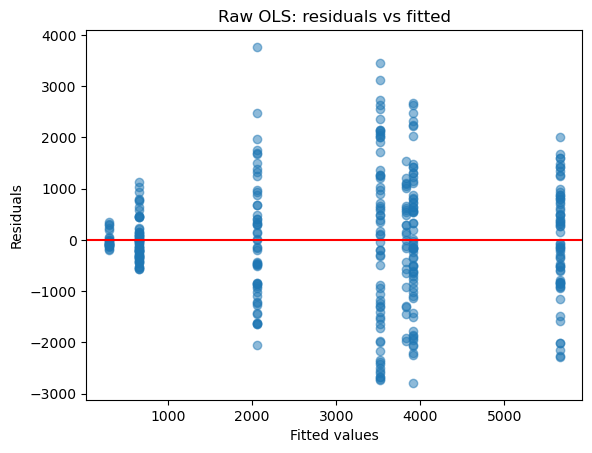

In [3]:
import matplotlib.pyplot as plt
plt.scatter(model_raw.fittedvalues, model_raw.resid, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Raw OLS: residuals vs fitted")
plt.show()

In [4]:
import numpy as np
model_log =smf.ols("np.log(ride_count) ~ C(season) * C(day_type)", data=daily).fit()
print(model_log.summary())

                            OLS Regression Results                            
Dep. Variable:     np.log(ride_count)   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     125.4
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           3.53e-92
Time:                        23:25:33   Log-Likelihood:                -336.91
No. Observations:                 365   AIC:                             689.8
Df Residuals:                     357   BIC:                             721.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

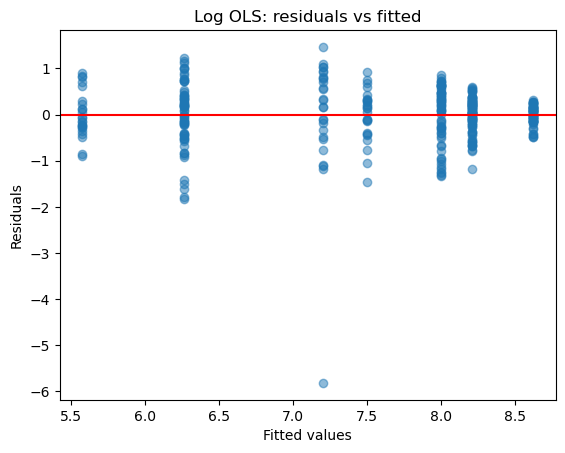

In [5]:
import matplotlib.pyplot as plt
plt.scatter(model_log.fittedvalues, model_log.resid, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Log OLS: residuals vs fitted")
plt.show()

In [6]:
import statsmodels.api as sm 
anova = sm.stats.anova_lm(model_log, typ=2)
anova 
anova["partial_eta_sq"] = anova["sum_sq"] / (anova["sum_sq"] + anova.loc["Residual", "sum_sq"])
anova.round(3)

,sum_sq,df,F,PR(>F),partial_eta_sq
C(season),304.218,3.0,267.405,0.000,0.692
C(day_type),31.322,1.0,82.594,0.000,0.188
C(season):C(day_type),1.597,3.0,1.404,0.241,0.012
Residual,135.383,357.0,NaN,NaN,0.500


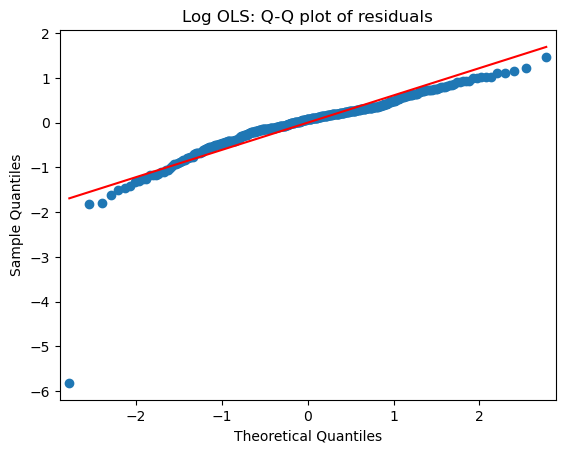

In [7]:
sm.qqplot(model_log.resid, line='s')
plt.title("Log OLS: Q-Q plot of residuals")
plt.show()

0.4969456781612243


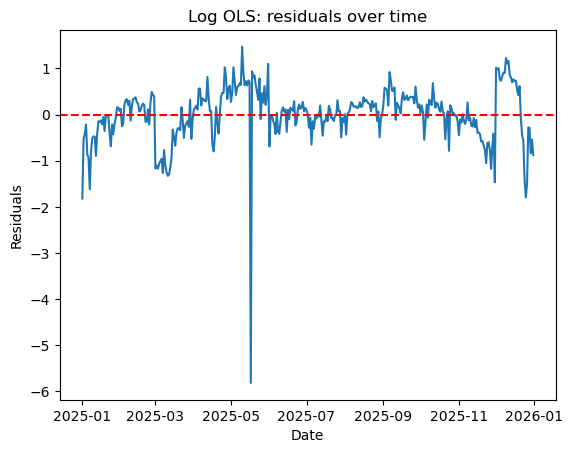

In [8]:
plt.plot(model_log.resid)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.title("Log OLS: residuals over time")
print(model_log.resid.autocorr())
plt.show()

In [9]:
daily_clean = daily.drop(pd.Timestamp('2025-05-17'))  # Remove the outlier date from the dataset
print(daily_clean.shape)  # Check the shape of the cleaned dataset


(364, 8)


In [10]:
# Same log model as model_log, but fitted on the data without 17 May (sensitivity analysis)
model_clean = smf.ols("np.log(ride_count) ~ C(season) * C(day_type)", data=daily_clean).fit()
print(model_clean.summary())

                            OLS Regression Results                            
Dep. Variable:     np.log(ride_count)   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     167.1
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          2.08e-108
Time:                        23:25:34   Log-Likelihood:                -281.77
No. Observations:                 364   AIC:                             579.5
Df Residuals:                     356   BIC:                             610.7
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [11]:
# ANOVA + partial eta squared for the model without 17 May, to compare with anova above
anova_clean = sm.stats.anova_lm(model_clean, typ=2)
anova_clean["partial_eta_sq"] = anova_clean["sum_sq"] / (anova_clean["sum_sq"] + anova_clean.loc["Residual", "sum_sq"])
anova_clean.round(3)

,sum_sq,df,F,PR(>F),partial_eta_sq
C(season),306.218,3.0,362.541,0.000,0.753
C(day_type),25.859,1.0,91.844,0.000,0.205
C(season):C(day_type),1.041,3.0,1.232,0.298,0.010
Residual,100.231,356.0,NaN,NaN,0.500


In [12]:
# Model 2 data: 2024 + 2025, without closed day (17 May 2025) in 2024 it was used  
daily_2y = daily_all[daily_all["year"].isin([2024, 2025]) & ~daily_all["closed"]]
print(daily_2y.shape)
print(daily_2y["year"].value_counts())

# Baseline: Model 1 formula refitted on the same 2 years
model_base = smf.ols("np.log(ride_count) ~ C(season) * C(day_type)", data=daily_2y).fit()
anova_base = sm.stats.anova_lm(model_base, typ=2)
anova_base["partial_eta_sq"] = anova_base["sum_sq"] / (anova_base["sum_sq"] + anova_base.loc["Residual", "sum_sq"])
anova_base.round(3)

(730, 8)
year
2024    366
2025    364
Name: count, dtype: int64


,sum_sq,df,F,PR(>F),partial_eta_sq
C(season),651.175,3.0,586.132,0.000,0.709
C(day_type),51.554,1.0,139.212,0.000,0.162
C(season):C(day_type),2.062,3.0,1.856,0.136,0.008
Residual,267.373,722.0,NaN,NaN,0.500


In [13]:
# Model 2: Model 1 + weather + holiday, on the same 2024-2025 data
model_2 = smf.ols("np.log(ride_count) ~ C(season) * C(day_type) + temp_mean + precip_mm + is_holiday",
                  data=daily_2y).fit()
anova_2 = sm.stats.anova_lm(model_2, typ=2)
anova_2["partial_eta_sq"] = anova_2["sum_sq"] / (anova_2["sum_sq"] + anova_2.loc["Residual", "sum_sq"])
print("R² baseline:", round(model_base.rsquared, 3), "| R² Model 2:", round(model_2.rsquared, 3))
anova_2.round(3)

R² baseline: 0.723 | R² Model 2: 0.849


,sum_sq,df,F,PR(>F),partial_eta_sq
C(season),104.101,3.0,171.200,0.000,0.417
C(day_type),52.169,1.0,257.384,0.000,0.264
is_holiday,13.380,1.0,66.013,0.000,0.084
C(season):C(day_type),2.402,3.0,3.950,0.008,0.016
temp_mean,100.539,1.0,496.029,0.000,0.408
precip_mm,20.498,1.0,101.131,0.000,0.123
Residual,145.733,719.0,NaN,NaN,0.500


### Baseline vs Model 2: does the season effect shrink?

Both models use the same data (2024 + 2025, 730 days, 17 May 2025 excluded because the system was closed) and the same log scale, so their R² values and sums of squares are directly comparable.

| | Baseline (season × day type) | Model 2 (+ temperature, precipitation, holiday) |
|---|---|---|
| R² | 0.723 | **0.849** |
| Residual sum of squares | 267.4 | 145.7 |
| Season: sum of squares / partial η² | 651.2 / 0.709 | **104.1 / 0.417** |
| Day type: partial η² | 0.162 | 0.264 |
| Interaction: p / partial η² | 0.136 / 0.008 | 0.008 / 0.016 |
| Temperature: partial η² | – | 0.408 |
| Precipitation: partial η² | – | 0.123 |
| Holiday: partial η² | – | 0.084 |

**Interpretation**
- **Weather and holidays improve the model:** R² rises from 0.72 to 0.85, so they explain about 45% of the variation the baseline left unexplained.
- **The season effect shrinks but does not disappear:** its sum of squares falls by about 84% (651 → 104), and its partial η² drops from 0.71 to 0.42. Most of the "season" effect in the baseline was really temperature. Season stays highly significant (p < .001), so a seasonal effect remains beyond weather, for example daylight, school and holiday periods, tourism and habits.
- **Temperature is almost as strong as season** (partial η² 0.41). Precipitation is clearly significant once season and temperature are controlled, even though its simple correlation with ride count was weak (r = −0.12).
- **Day type:** its sum of squares is unchanged (51.6 vs 52.2). The higher partial η² only reflects the smaller residual, because partial η² depends on the other terms in the model.
- **Interaction:** it becomes significant (p = .008) only because the residual noise is smaller. Its effect size is tiny (partial η² = 0.016), so the weekday–weekend gap in percentage terms is practically the same across seasons.

In [14]:
# Model 2 coefficients as % change in daily rides (log model -> exp)
ci = model_2.conf_int()
effects = pd.DataFrame({
    "coef": model_2.params,
    "pct_change": (np.exp(model_2.params) - 1) * 100,
    "ci_low": (np.exp(ci[0]) - 1) * 100,
    "ci_high": (np.exp(ci[1]) - 1) * 100,
    "p": model_2.pvalues,
})
effects.round(3)

,coef,pct_change,ci_low,ci_high,p
Intercept,7.795,242682.698,221214.709,266233.126,0.000
C(season)[T.Spring],-0.327,-27.879,-35.460,-19.407,0.000
C(season)[T.Summer],-0.273,-23.890,-32.746,-13.867,0.000
C(season)[T.Winter],-1.241,-71.084,-74.590,-67.094,0.000
C(day_type)[T.Weekend],-0.603,-45.305,-52.694,-36.761,0.000
is_holiday[T.True],-0.792,-54.698,-62.587,-45.146,0.000
C(season)[T.Spring]:C(day_type)[T.Weekend],0.035,3.557,-15.650,27.137,0.738
C(season)[T.Summer]:C(day_type)[T.Weekend],0.174,19.019,-2.944,45.951,0.094
C(season)[T.Winter]:C(day_type)[T.Weekend],-0.185,-16.878,-32.485,2.338,0.081
temp_mean,0.075,7.801,7.089,8.517,0.000


### Model 2 coefficients as % effects

Because the response is log(ride_count), a coefficient b is a multiplicative effect: % change = (exp(b) − 1) × 100. Each effect holds the other variables constant. The reference day is an **autumn weekday that is not a holiday**.

| Variable | % change in daily rides | 95% CI |
|---|---|---|
| Temperature (+1 °C) | **+7.8%** | +7.1% to +8.5% |
| Precipitation (+1 mm) | **−2.9%** | −3.4% to −2.3% |
| Public holiday | **−54.7%** | −62.6% to −45.1% |
| Weekend (autumn) | −45.3% | −52.7% to −36.8% |
| Winter vs autumn | −71.1% | −74.6% to −67.1% |
| Spring vs autumn | −27.9% | −35.5% to −19.4% |
| Summer vs autumn | **−23.9%** | −32.7% to −13.9% |

**Interpretation**
- **Weather:** a day that is 10 °C warmer has about 2.1 times as many rides (1.078¹⁰), and a day with 10 mm of precipitation has about 25% fewer (0.971¹⁰).
- **Holidays** almost halve the number of rides, because commuting trips disappear.
- **At the same temperature, summer has about 24% fewer rides than autumn.** In Model 1, summer was higher than autumn, so that whole advantage came from temperature. The remaining negative summer effect likely reflects the summer holiday (fellesferie, not modelled; see the limitations) and the lack of school and university commuting.
- **Winter** is still about 71% lower even at the same temperature: darkness, snow and ice, and fewer bikes in service.
- **Intercept:** not a percentage. exp(7.795) ≈ 2,428 rides is the prediction for an autumn weekday at 0 °C, with no rain and no holiday.
- **Interaction terms:** none is significant on its own (p = .74, .09, .08), but together they are significant in the ANOVA (p = .008). The ANOVA tests the three terms jointly. The effect is small, so no single term is strong enough on its own.

**In plain words**
- **Temperature increases bike use:** the warmer the day, the more people ride (about +8% per °C).
- **Precipitation decreases bike use:** every mm of rain or snow lowers rides by about 3%, so a wet day (10 mm) has about a quarter fewer rides.
- **Season still matters after weather:** even at the same temperature and rain, winter has far fewer rides, and spring and summer have fewer rides than autumn.
- **Summer looks busiest only because it is warm.** Once temperature is accounted for, autumn is the busiest season.
- **Weekends (−45%) and public holidays (−55%) reduce bike use strongly,** which shows that commuting is the main use of the city bikes.

In [15]:
# 5.4 Multicollinearity check: VIF for every column of Model 2's design matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = model_2.model.exog
vif = pd.Series([variance_inflation_factor(X, i) for i in range(X.shape[1])],
                index=model_2.model.exog_names)
print(daily_2y.groupby("season")["temp_mean"].mean().round(1))
vif.round(2)

season
Autumn     7.4
Spring     7.3
Summer    16.2
Winter    -2.9
Name: temp_mean, dtype: float64


Intercept                                     8.01
C(season)[T.Spring]                           2.17
C(season)[T.Summer]                           2.70
C(season)[T.Winter]                           2.91
C(day_type)[T.Weekend]                        4.00
is_holiday[T.True]                            1.04
C(season)[T.Spring]:C(day_type)[T.Weekend]    2.60
C(season)[T.Summer]:C(day_type)[T.Weekend]    2.66
C(season)[T.Winter]:C(day_type)[T.Weekend]    2.53
temp_mean                                     2.90
precip_mm                                     1.04
dtype: float64

### Multicollinearity check (VIF)

Temperature and season overlap, because summer is warm and winter is cold. If two predictors overlap too much, the model cannot separate their effects and the coefficients become unstable. VIF (variance inflation factor) = 1 / (1 − R²ⱼ), where R²ⱼ is how well predictor j is explained by the other predictors. Lower is better: 1 means no overlap. Rule of thumb: VIF > 5 is a warning and VIF > 10 is a serious problem.

| Predictor | VIF |
|---|---|
| temp_mean | 2.90 |
| Season dummies (Spring / Summer / Winter) | 2.17 / 2.70 / 2.91 |
| precip_mm / is_holiday | 1.04 / 1.04 |
| Weekend | 4.00 (raised by the interaction terms, which are built from it) |

The intercept's VIF is not interpreted.

**Interpretation**
- **All VIFs are below 5, so multicollinearity is not a problem.** For temperature, R²ⱼ ≈ 0.66: about two-thirds of its variation is shared with the other predictors. Its standard error is inflated by √2.9 ≈ 1.7, but its 95% CI is still narrow (+7.1% to +8.5% per °C). The model can separate the temperature effect from the season effect.
- **Mean temperature by season:** Autumn 7.4 °C, Spring 7.3 °C, Summer 16.2 °C, Winter −2.9 °C. Spring and autumn have almost the same mean temperature, yet spring has about 28% fewer rides at the same temperature. So the season effect is not only weather. Habits and the academic calendar likely play a role.

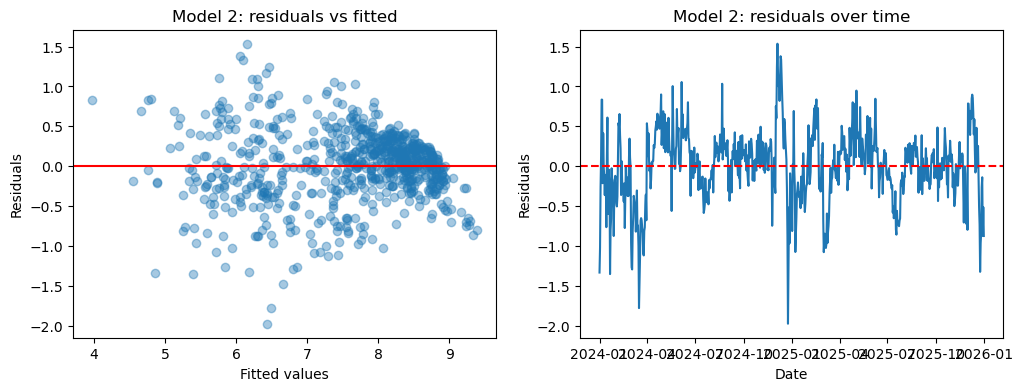

DW baseline: 0.385 | DW Model 2: 0.467
season
Autumn    0.240
Spring    0.533
Summer    0.334
Winter    0.592
dtype: float64


In [16]:
# 5.5 Residual diagnostics for Model 2
from statsmodels.stats.stattools import durbin_watson
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(model_2.fittedvalues, model_2.resid, alpha=0.4)
axes[0].axhline(0, color="red")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Model 2: residuals vs fitted")
axes[1].plot(model_2.resid)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Date", ylabel="Residuals", title="Model 2: residuals over time")
plt.show()
print("DW baseline:", round(durbin_watson(model_base.resid), 3), "| DW Model 2:", round(durbin_watson(model_2.resid), 3))
print(model_2.resid.groupby(daily_2y["season"]).std().round(3))

### Residual diagnostics for Model 2

| Check | Baseline | Model 2 |
|---|---|---|
| Durbin–Watson (2 = no autocorrelation) | 0.385 | **0.467** |
| Residual standard deviation (log scale) | 0.61 | 0.45 |

| Season | Residual std (Model 2) |
|---|---|
| Autumn | 0.240 |
| Summer | 0.334 |
| Spring | 0.533 |
| Winter | **0.592** |

**Interpretation**
- **Independence is still violated.** DW improves only slightly (0.39 → 0.47) and is still far from 2. The residuals over time move in blocks: below zero in March (both years), in July (fellesferie) and around Christmas, and above zero in early December 2024. Weather explains day-to-day changes, but not these slower patterns. Consequence: the standard errors are too small and the p-values are optimistic. The main effects are far beyond this concern (F = 101 to 496), but the borderline interaction (p = .008) should be read with caution.
- **Unequal variance remains.** The residuals vs fitted plot is a reverse funnel: wide spread on low-ride days (winter, early spring) and narrow on busy days. The residual std is about 2.5 times larger in winter (0.59) than in autumn (0.24). On days with few rides, small random events (snow, a closed station) have a large relative effect.
- **The very hottest days are over-predicted.** At the right end of the plot (fitted > 8.8) the residuals are mostly negative. On the 14 days above 21 °C the mean residual is −0.62, so the linear temperature effect (+7.8% per °C) does not continue on hot days. A possible saturation, which tree-based models in step 6 may capture.
- **Overall:** Model 2 is a clear improvement (smaller residuals, R² 0.85), and the main conclusions hold. Its remaining problems (time clustering, unequal variance, non-linearity at high temperatures) are limitations to report, and they motivate the flexible prediction models in step 6.